# Basics of Mobile Robotics - Project

## Table of Contents

- [Introduction](#introduction)
    - [Group](#group) 
- [Camera and Thymio Connection](#camera-and-thymio-connexion)
- [Vision Processing](#vision-processing)
- [Filtering](#filtering)
- [Navigation](#navigation)
    - [Global Navigation](#global-navigation)
    - [Local Navigation](#local-navigation)
- [Results](#results)
- [Conclusion](#conclusion)

## Introduction 
This project is part of the course *Basics of Mobile Robotics (MICRO-452)* at EPFL and is initially made by group of four students. The class is given by Professor Francesco Mondada from [MOBOTS lab](https://www.epfl.ch/labs/mobots/).

### Goal of the project 
This project aim to implement diverse algorithme seen in course. 
- Autonomous navigation through a specific goal following the optimal path. 
- Unexpected object avoidance. 
- Keep track of the goal if blind through a extended Kalman filter. 
- Be able to reach any position in the predefined map.

### Group
Our team consists of three first-year Master's students in Robotics at EPFL. The work load has been equally separated between members. The final assembly of the code has been done by everyone. 
| Name            | SCIPER | Role                       |
|-----------------|--------|----------------------------|
| Linus  Crugnola | 340864 | Filtering                  |
| Alexis Bollack  | 406474 | Local & Global navigation  |
| Maxime Luyet    | 345770 | Vision                     |



In [50]:
%reload_ext autoreload
%autoreload 2

import sys
import time
sys.path.append('./src')

#from filtering import *
from src.vision import Vision 
from src.global_navigation import GlobalNavigation
from src.local_navigation import LocalNavigation
from src.filtering import KalmanFilter
#from utils import utils

In [51]:
#Constants
CAM_ID = 0

In [82]:
vision = Vision(CAM_ID)
vision.message_from_vision()

#Declare your other instance here 

Vision module is correctly linked.


## Camera and Thymio connexion 

Here we setup the connexion to the other perhiphericals. 

### Camera connexion 

In [76]:
#ERREUR, la condition vision.webcam_connextion() 
#est exécutée 2 fois pour une raison inconnue 
try:
    print("Connexion to camera ...")

    if not vision.webcam_connextion():
        print("Failed to connect to camera")
        exit(1)
    else:
        print("Webcam connected")

    # start_time = time.time()
    # while time.time() - start_time < 3:
    #     original_frame = vision._get_original_frame()
    #     utils.display_frames(original_frame, None, None)
except KeyboardInterrupt: 
    print("Program interrupted by user.")
    pass
finally: 
    vision.disconnect_webcam()

Connexion to camera ...
Webcam connected successfully!
Webcam connected
Webcam deconnected
Webcam connected successfully!
Webcam connected
Webcam deconnected


In [214]:
vision.webcam_connextion()

Webcam connected successfully!


True

In [212]:
vision.disconnect_webcam()

Webcam disconnected


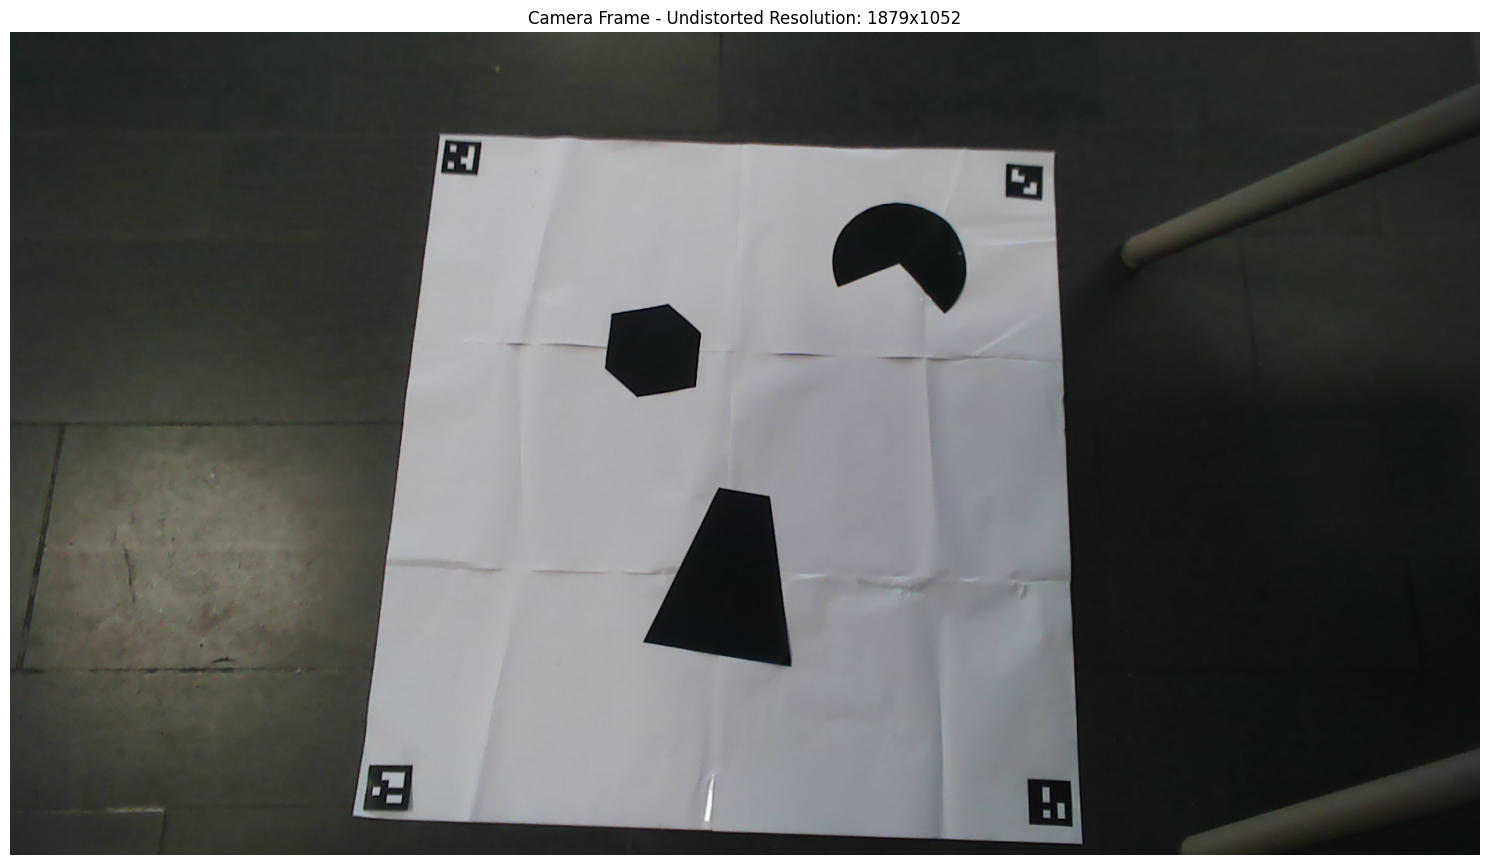

Frame shape (Height x Width x Channels): (1052, 1879, 3)
Frame captured successfully!


In [211]:
#RETESEER LES VALEURS DE LA CAMERA 

#=============================================
#Test of camera capture and undistortion
#=============================================

import matplotlib.pyplot as plt

# Capture frame from camera (undistorted frame)
frame = vision._get_frame()

if frame is not None:
    # Convert BGR (OpenCV) to RGB (matplotlib)
    frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    
    # Display the image
    plt.figure(figsize=(15, 10))
    plt.imshow(frame_rgb)
    plt.title(f"Camera Frame - Undistorted Resolution: {frame.shape[1]}x{frame.shape[0]}")
    plt.axis('off')
    plt.tight_layout()
    plt.show()
    
    print(f"Frame shape (Height x Width x Channels): {frame.shape}")
    print(f"Frame captured successfully!")
else:
    print("Failed to capture frame")